# 02 – Baseline forecasts
Scores simple reference forecasts on a held-out test period. The ML model in notebook 03 must beat these numbers to justify its extra complexity.

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from occforecast.load import load_occupancy
from occforecast.resample import resample_all
from occforecast.baselines import weekly_profile, persistence
from occforecast.evaluate import score

DATA = "../data/raw/5occupancySensor_MayToDec2024_9MRows.csv"
SPLIT = pd.Timestamp("2025-07-01", tz="Australia/Melbourne")

events = load_occupancy(DATA)
series = resample_all(events, freq="15min", max_hold="48h").sort_index()
labels = {s: f"Space {chr(65 + i)}" for i, s in enumerate(sorted(events["space"].unique()))}
series["label"] = series["space"].map(labels)

## 1. Chronological train/test split
Data before 1 July 2025 is used for training and data from 1 July 2025 onwards for testing. The split is by date, not random, because a forecaster can only learn from the past: a random split would let the model see days on either side of each test day and give over-optimistic results. The test period covers a semester, the summer shutdown, and the start of the next semester.

In [2]:
for name, g in series.groupby("label"):
    y = g["headcount_mean"]
    n_train = y[y.index < SPLIT].notna().sum()
    n_test = y[y.index >= SPLIT].notna().sum()
    print(f"{name}: train {n_train:>6,} intervals | test {n_test:>6,} intervals")

Space A: train 54,742 intervals | test 28,413 intervals
Space B: train 46,504 intervals | test 28,409 intervals
Space C: train 23,417 intervals | test      0 intervals
Space D: train 54,855 intervals | test 28,413 intervals
Space E: train 46,504 intervals | test 28,256 intervals


## 2. Baseline forecasts
- **Weekly profile:** the average of all training values at the same weekday and time-of-day.
- **Persistence (1 day / 7 days):** the observed value exactly 1 or 7 days earlier. Valid for a 24-hour-ahead forecast, because that value is already known when the forecast is made.

Each is scored on the test period with MAE and RMSE (people) and F1 for the occupied/unoccupied decision (occupied = mean headcount ≥ 0.5).

In [3]:
results, forecasts = [], {}
for name, g in series.groupby("label"):
    y = g["headcount_mean"]
    train, test = y[y.index < SPLIT], y[y.index >= SPLIT].dropna()
    if test.empty or train.dropna().empty:
        print(f"{name}: skipped (no data on one side of the split)")
        continue
    preds = {
        "Weekly profile": weekly_profile(train, test.index),
        "Persistence (1 day)": persistence(y, test.index, lag="1D"),
        "Persistence (7 days)": persistence(y, test.index, lag="7D"),
    }
    forecasts[name] = pd.DataFrame({"Actual": test, **preds})
    for method, p in preds.items():
        results.append({"Space": name, "Method": method, **score(test, p)})

table = pd.DataFrame(results).set_index(["Space", "Method"])
display(table.round(3))
display(table.groupby("Method")[["MAE", "RMSE", "F1"]].mean().round(3))

Space C: skipped (no data on one side of the split)


MAE   RMSE     F1      n
Space   Method                                          
Space A Weekly profile        0.378  0.704  0.674  28413
        Persistence (1 day)   0.347  0.922  0.682  28413
        Persistence (7 days)  0.324  0.898  0.707  28413
Space B Weekly profile        0.620  0.906  0.522  28409
        Persistence (1 day)   0.554  0.950  0.489  28409
        Persistence (7 days)  0.561  0.899  0.445  28409
Space D Weekly profile        0.389  0.632  0.806  28413
        Persistence (1 day)   0.474  0.886  0.731  28413
        Persistence (7 days)  0.387  0.739  0.814  28413
Space E Weekly profile        0.810  1.975  0.709  28256
        Persistence (1 day)   0.951  2.664  0.641  28160
        Persistence (7 days)  0.889  2.627  0.659  28100

,MAE,RMSE,F1
Method,,,
Persistence (1 day),0.582,1.355,0.636
Persistence (7 days),0.540,1.291,0.656
Weekly profile,0.549,1.055,0.678


**Findings:** no baseline wins on every metric. Averaged over spaces A, B, D and E, 7-day persistence has the lowest MAE (0.540), but the weekly profile has a clearly lower RMSE (1.055 vs 1.291) and the best F1 (0.678). Persistence copies the exact shape of the previous week, which is good when weeks repeat but produces large errors when they don't. The weekly profile averages many weeks, so it rarely misses badly, but it underestimates peaks and keeps a small non-zero level overnight and at weekends. 1-day persistence is worst overall, because e.g. Monday's forecast copies Sunday. Space E is hardest (RMSE ≈ 2, peaks up to 72 people) and Space B has the lowest F1 (≈ 0.5), consistent with short scheduled sessions.

**Targets for the ML model:** MAE < 0.54, RMSE < 1.06, F1 > 0.68 (beat the best baseline on each metric).

## 3. Forecast vs actual for one test week

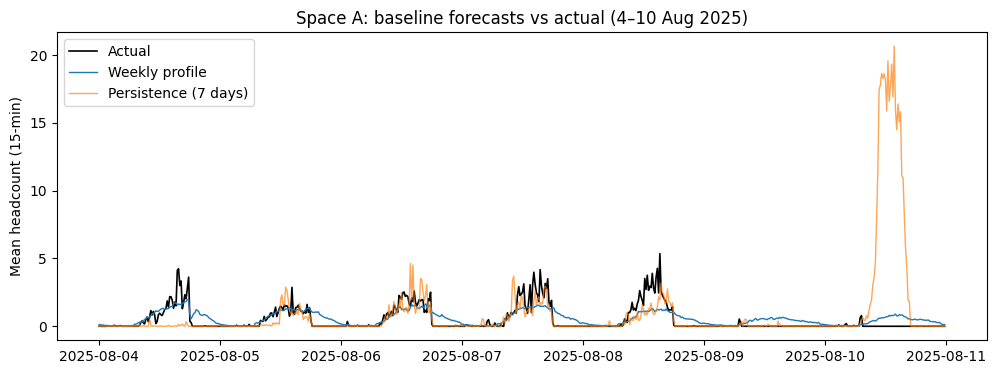

In [4]:
name = "Space A"
f = forecasts[name]
wk = f.loc["2025-08-04":"2025-08-10"]        # a mid-semester week
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(wk.index, wk["Actual"], color="black", lw=1.2, label="Actual")
ax.plot(wk.index, wk["Weekly profile"], lw=1, label="Weekly profile")
ax.plot(wk.index, wk["Persistence (7 days)"], lw=1, alpha=0.7, label="Persistence (7 days)")
ax.set_ylabel("Mean headcount (15-min)")
ax.set_title(f"{name}: baseline forecasts vs actual (4–10 Aug 2025)")
ax.legend()
plt.show()

**Findings:** the weekly profile follows the daily shape but flattens the peaks (≈ 1.5 forecast vs ≈ 4 actual) and stays slightly above zero overnight and on the weekend. 7-day persistence tracks weekday peaks more closely, but it repeats a one-off event of ≈ 20 people from Sunday 3 Aug as a forecast for Sunday 10 Aug, when the space was empty. This single kind of error explains persistence's much higher RMSE.